<a href="https://colab.research.google.com/github/Anagha-code12/AI-ML-Project/blob/main/AI_ML_Part_3_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q tensorflow

In [ ]:
import zipfile
import os
import pandas as pd
import numpy as np

from google.colab import files

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.20.0


In [ ]:
uploaded = files.upload()

Saving Chemicaldata.zip to Chemicaldata (1).zip


In [ ]:
zip_name = list(uploaded.keys())[0]

extract_path="/content/chemical"

with zipfile.ZipFile(zip_name,'r') as zip_ref:
    zip_ref.extractall(extract_path)

csv_file=None

for root,dirs,files in os.walk(extract_path):
    for file in files:
        if file.endswith(".csv"):
            csv_file=os.path.join(root,file)

print(csv_file)

/content/chemical/chemical_process_timeseries.csv


In [ ]:
df=pd.read_csv(csv_file)

df.head()

,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,selectivity,yield_pct,vibration_rms,motor_current,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min
0,2024-01-01 00:00:00,A,A_R1,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,...,91.927424,82.032893,1.470297,45.882315,41.294083,180.0,12.0,0,0.0,NaN
1,2024-01-01 00:01:00,A,A_R1,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,...,91.581466,81.301503,1.425847,46.755905,42.080314,180.0,12.0,0,0.0,NaN
2,2024-01-01 00:02:00,A,A_R1,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,...,91.895056,82.006626,1.448190,NaN,NaN,NaN,12.0,0,NaN,NaN
3,2024-01-01 00:03:00,A,A_R1,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,...,91.544885,81.562261,1.473448,45.862171,41.275954,180.0,12.0,0,0.0,NaN
4,2024-01-01 00:04:00,A,A_R1,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,...,92.258005,82.411124,1.523491,46.880227,42.192204,180.0,12.0,0,NaN,NaN


In [ ]:
df['timestamp']=pd.to_datetime(df['timestamp'])

In [ ]:
encoder=LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col]=encoder.fit_transform(df[col])

In [ ]:
df.dropna(inplace=True)
display(df.head())

,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,selectivity,yield_pct,vibration_rms,motor_current,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min
2900,2024-01-03 00:20:00,0,0,1.401343,182.052477,15.482909,101.964901,80.674985,301.205115,0.728210,...,91.959637,82.064367,1.435293,46.176875,41.559188,180.0,12.0,2,5.000000,878.0
2903,2024-01-03 00:23:00,0,0,1.402783,183.520648,15.715951,100.605515,79.134836,300.374220,0.734083,...,91.717382,81.858304,1.517250,46.301054,41.670948,180.0,12.0,2,5.068337,875.0
2908,2024-01-03 00:28:00,0,0,1.405183,182.376605,15.649220,98.896895,79.097502,303.310903,0.729506,...,91.681029,81.902385,1.483881,46.218474,41.596627,180.0,12.0,2,5.182232,870.0
2910,2024-01-03 00:30:00,0,0,1.406143,182.529955,15.561025,99.763399,79.941459,301.898492,0.730120,...,91.741027,82.021405,1.511876,46.131350,41.518215,180.0,12.0,2,5.227790,868.0
2916,2024-01-03 00:36:00,0,0,1.409023,182.417902,15.703517,100.185459,78.466765,303.591418,0.729672,...,92.143868,82.313074,1.433205,45.852515,41.267264,180.0,12.0,2,5.364465,862.0


In [ ]:
df=df.drop("timestamp",axis=1)

In [ ]:
target='time_to_fault_min'

In [ ]:
X=df.drop(target,axis=1)

y=df[target]

In [ ]:
scaler=MinMaxScaler()

X=scaler.fit_transform(X)

y=y.values

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
X_train=X_train.reshape((X_train.shape[0],1,X_train.shape[1]))

X_test=X_test.reshape((X_test.shape[0],1,X_test.shape[1]))

print(X_train.shape)

(7781, 1, 19)


In [ ]:
model=Sequential()

model.add(LSTM(
    128,
    input_shape=(1,X_train.shape[2]),
    return_sequences=True
))

model.add(Dropout(0.2))

model.add(LSTM(64))

model.add(Dropout(0.2))

model.add(Dense(32,activation='relu'))

model.add(Dense(1))

In [ ]:
model.compile(

optimizer='adam',

loss='mse',

metrics=['mae']

)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 1, 128)         │        75,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127,297 (497.25 KB)

 Trainable params: 127,297 (497.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early=EarlyStopping(

monitor='val_loss',

patience=5,

restore_best_weights=True

)

In [ ]:
history=model.fit(

X_train,

y_train,

epochs=5,

batch_size=64,

validation_split=0.2,

callbacks=[early]

)

Epoch 1/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 319423.5312 - mae: 459.5745 - val_loss: 287618.4062 - val_mae: 422.7292
Epoch 2/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 257885.6719 - mae: 396.4655 - val_loss: 223232.9688 - val_mae: 358.5776
Epoch 3/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 193558.8438 - mae: 334.7345 - val_loss: 164851.4375 - val_mae: 307.0565
Epoch 4/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 144954.2031 - mae: 292.9737 - val_loss: 129258.1875 - val_mae: 281.7171
Epoch 5/5
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 119140.3672 - mae: 275.1334 - val_loss: 115282.6484 - val_mae: 275.6946


In [ ]:
print(history.history.keys())

dict_keys(['loss', 'mae', 'val_loss', 'val_mae'])


In [ ]:
loss,mae=model.evaluate(X_test,y_test)

print("MAE =",mae)

61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 120156.2266 - mae: 280.2439
MAE = 280.243896484375


In [ ]:
prediction=model.predict(X_test)

prediction[:10]

61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


array([[412.27844],
       [412.23843],
       [412.28946],
       [412.2846 ],
       [412.2785 ],
       [412.21286],
       [412.28897],
       [412.2785 ],
       [412.28986],
       [412.27927]], dtype=float32)

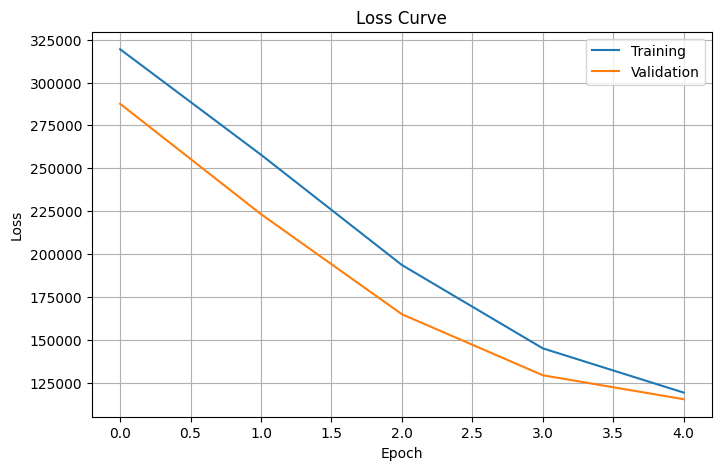

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])

label='Training Loss'

plt.plot(history.history['val_loss'])

label='Validation Loss'

plt.legend(["Training","Validation"])

plt.grid(True)

plt.title("Loss Curve")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.show()

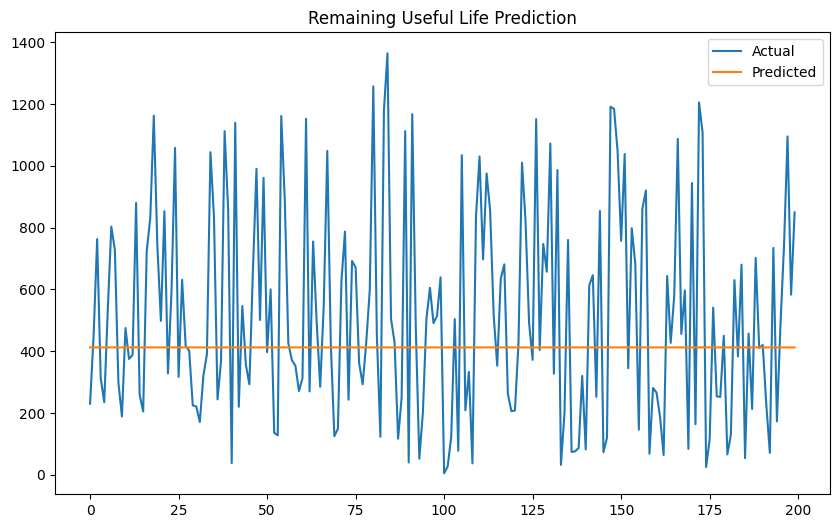

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(y_test[:200],label="Actual")

plt.plot(prediction[:200],label="Predicted")

plt.legend()

plt.title("Remaining Useful Life Prediction")

plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae=mean_absolute_error(y_test,prediction)

mse=mean_squared_error(y_test,prediction)

rmse=np.sqrt(mse)

r2=r2_score(y_test,prediction)

print("MAE :",mae)

print("MSE :",mse)

print("RMSE :",rmse)

print("R2 :",r2)

MAE : 280.24388095898837
MSE : 120156.217493333
RMSE : 346.6355687077323
R2 : -0.05369336434146477


In [ ]:
nan_count = df['time_to_fault_min'].isnull().sum()
print(f"Number of NaN values in 'time_to_fault_min': {nan_count}")

Number of NaN values in 'time_to_fault_min': 0


In [ ]:
model.save("PredictiveMaintenanceLSTM.h5")

print("Saved Successfully")

Saved Successfully


In [ ]:
from google.colab import files
files.download("PredictiveMaintenanceLSTM.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>